<a href="https://colab.research.google.com/github/HadyShibli/ter_1/blob/main/MyFirstColabNotebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import time
print("Hello world!")
!pip install numpy


Hello world!


In [7]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


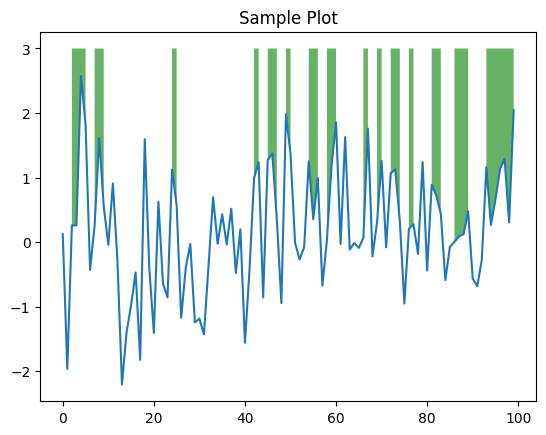

In [8]:
import numpy as np
from matplotlib import pyplot as plt

y = np.random.randn(100)
x = [x for x in range(len(y))]

plt.plot(x, y, '-')
plt.fill_between(x, y, 3, where=(y > 0), facecolor='g', alpha=0.6)

plt.title("Sample Plot")
plt.show()

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
from google.colab import drive
import os
import ipywidgets as widgets
from IPython.display import display

# 1. חיבור ל-Google Drive
drive.mount('/content/drive')

# נתיב לקובץ הנתונים
file_path = '/content/drive/MyDrive/students.txt'

# 2. קריאת הנתונים מהקובץ
def load_students():
    students = []
    if os.path.exists(file_path):
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                line = line.strip()
                if line:
                    parts = [p.strip() for p in line.split(',')]
                    if len(parts) >= 5:
                        students.append({
                            'first_name': parts[0],
                            'last_name': parts[1],
                            'email': parts[2],
                            'courses': parts[3],
                            'link': parts[4]
                        })
    return students

students_data = load_students()
student_options = [f"{s['first_name']} {s['last_name']}" for s in students_data]

# 3. יצירת רכיבי הממשק (Widgets) בשפה העברית
w_dropdown = widgets.Dropdown(
    options=student_options if student_options else ['אין נתונים ב-students.txt'],
    description='בחר סטודנט:'
)

txt_first = widgets.Text(description='שם פרטי:')
txt_last = widgets.Text(description='שם משפחה:')
txt_email = widgets.Text(description='אימייל:')
txt_courses = widgets.Text(description='קורסים:')
txt_link = widgets.Text(description='קישור:')
txt_fav_show = widgets.Text(description='תוכנית אהובה:')

btn_update = widgets.Button(description='עדכן קובץ', button_style='success')
output_area = widgets.Output()

# 4. עדכון תיבות הטקסט בעקבות שינוי בתיבת הבחירה
def on_student_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        selected_name = change['new']
        for s in students_data:
            if f"{s['first_name']} {s['last_name']}" == selected_name:
                txt_first.value = s['first_name']
                txt_last.value = s['last_name']
                txt_email.value = s['email']
                txt_courses.value = s['courses']
                txt_link.value = s['link']
                break

w_dropdown.observe(on_student_change)

# טעינת נתוני הסטודנט הראשון כברירת מחדל
if students_data:
    txt_first.value = students_data[0]['first_name']
    txt_last.value = students_data[0]['last_name']
    txt_email.value = students_data[0]['email']
    txt_courses.value = students_data[0]['courses']
    txt_link.value = students_data[0]['link']

# 5. כתיבת השורה החדשה לקובץ בלחיצה על הכפתור
def on_button_click(b):
    with output_area:
        output_area.clear_output()
        new_line = f"\n{txt_first.value}, {txt_last.value}, {txt_email.value}, {txt_courses.value}, {txt_link.value}, {txt_fav_show.value}"
        with open(file_path, 'a', encoding='utf-8') as f:
            f.write(new_line)
        print("הנתונים והתוכנית האהובה עודכנו בהצלחה ב-students.txt!")

btn_update.on_click(on_button_click)

# 6. הצגת הטופס במסך
display(w_dropdown, txt_first, txt_last, txt_email, txt_courses, txt_link, txt_fav_show, btn_update, output_area)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Dropdown(description='בחר סטודנט:', options=('Hady Shibli', 'Ebraheem Yaseen'), value='Hady Shibli')

Text(value='Hady', description='שם פרטי:')

Text(value='Shibli', description='שם משפחה:')

Text(value='hady@braude.ac.il', description='אימייל:')

Text(value='Python;Cloud', description='קורסים:')

Text(value='https://google.com', description='קישור:')

Text(value='', description='תוכנית אהובה:')

Button(button_style='success', description='עדכן קובץ', style=ButtonStyle())

Output()